# 4. Keyphrase Extraction

## Objective
Identify recurring phrases in positive and negative IMDb reviews to understand common praise and complaints.

## Approach
- Use YAKE for unsupervised keyphrase extraction.
- Extract phrases from the original review text.
- Compare keyphrase patterns across positive and negative reviews.
- Visualize the most frequent extracted phrases.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yake

from pathlib import Path
from collections import Counter

In [2]:
# Loading the processed dataset
data_path = Path("../dataset/processed/imdb_reviews_cleaned.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print(df["sentiment"].value_counts())
df.head(3)

Dataset shape: (49582, 3)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


,review,sentiment,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,a wonderful little production. the filming tec...
2,I thought this was a wonderful way to spend ti...,positive,i thought this was a wonderful way to spend ti...


In [3]:
# Extracting keyphrases from a single review using YAKE for testing purposes
sample_review = df.loc[
    df["sentiment"] == "positive", "review"
].iloc[1]

kw_extractor = yake.KeywordExtractor(
    lan="en",
    n=3,
    dedupLim=0.9,
    top=10
)

keywords = kw_extractor.extract_keywords(sample_review)

for phrase, score in keywords:
    print(f"{phrase:<35} {score:.4f}")

Michael Sheen                       0.0539
Williams' diary entries             0.0828
wonderful little production         0.0848
entire piece                        0.0931
wonderful                           0.1224
filming technique                   0.1282
piece                               0.1305
performed piece                     0.1377
Halliwell                           0.1440
references to Williams'             0.1442


One important observation: YAKE extracts a mixture of useful themes, names, and generic phrases. That's normal for an unsupervised keyphrase extractor.

In [4]:
sample_size = 500

sample_df = (
    df.groupby("sentiment", group_keys=False)
    .sample(n=sample_size, random_state=42)
    .reset_index(drop=True)
)

In [5]:
def extract_keyphrases(text, extractor, top_n=10):
    keywords = extractor.extract_keywords(str(text))
    return [phrase for phrase, score in keywords[:top_n]]


sample_df["keyphrases"] = sample_df["review"].apply(
    lambda text: extract_keyphrases(text, kw_extractor)
)

print(sample_df["sentiment"].value_counts())

sentiment
negative    500
positive    500
Name: count, dtype: int64


In [6]:
from collections import Counter

def get_top_phrases(data, sentiment, top_n=20):
    phrases = [
        phrase.lower()
        for phrase_list in data.loc[
            data["sentiment"] == sentiment, "keyphrases"
        ]
        for phrase in phrase_list
    ]

    return Counter(phrases).most_common(top_n)


positive_phrases = get_top_phrases(sample_df, "positive")
negative_phrases = get_top_phrases(sample_df, "negative")

print("Top positive-review phrases:")
for phrase, count in positive_phrases:
    print(f"{phrase:<35} {count}")

print("\nTop negative-review phrases:")
for phrase, count in negative_phrases:
    print(f"{phrase:<35} {count}")


Top positive-review phrases:
movie                               98
film                                73
good                                16
time                                15
story                               14
great                               14
people                              14
show                                13
years ago                           10
loved                               10
movies                              10
watch                               9
horror                              8
love                                8
years                               8
acting                              7
series                              7
dvd                                 6
bad                                 6
watched                             6

Top negative-review phrases:
movie                               134
film                                85
bad                                 34
good                                20
show         

In [7]:
generic_terms = {
    "movie", "movies", "film", "films",
    "show", "shows", "story", "stories",
    "people", "time", "year", "years",
    "guy", "word", "lot", "main"
}


def get_top_phrases(data, sentiment, top_n=20):
    phrases = [
        phrase.lower()
        for phrase_list in data.loc[
            data["sentiment"] == sentiment, "keyphrases"
        ]
        for phrase in phrase_list
        if phrase.lower() not in generic_terms
    ]

    return Counter(phrases).most_common(top_n)


positive_phrases = get_top_phrases(sample_df, "positive")
negative_phrases = get_top_phrases(sample_df, "negative")

print("Top positive-review phrases:")
for phrase, count in positive_phrases:
    print(f"{phrase:<35} {count}")

print("\nTop negative-review phrases:")
for phrase, count in negative_phrases:
    print(f"{phrase:<35} {count}")

Top positive-review phrases:
good                                16
great                               14
years ago                           10
loved                               10
watch                               9
horror                              8
love                                8
acting                              7
series                              7
dvd                                 6
bad                                 6
watched                             6
enjoyed                             5
episode                             5
great movie                         5
day                                 5
watching                            5
film festival                       5
funny                               5
pretty                              4

Top negative-review phrases:
bad                                 34
good                                20
acting                              10
funny                               10
plot                 

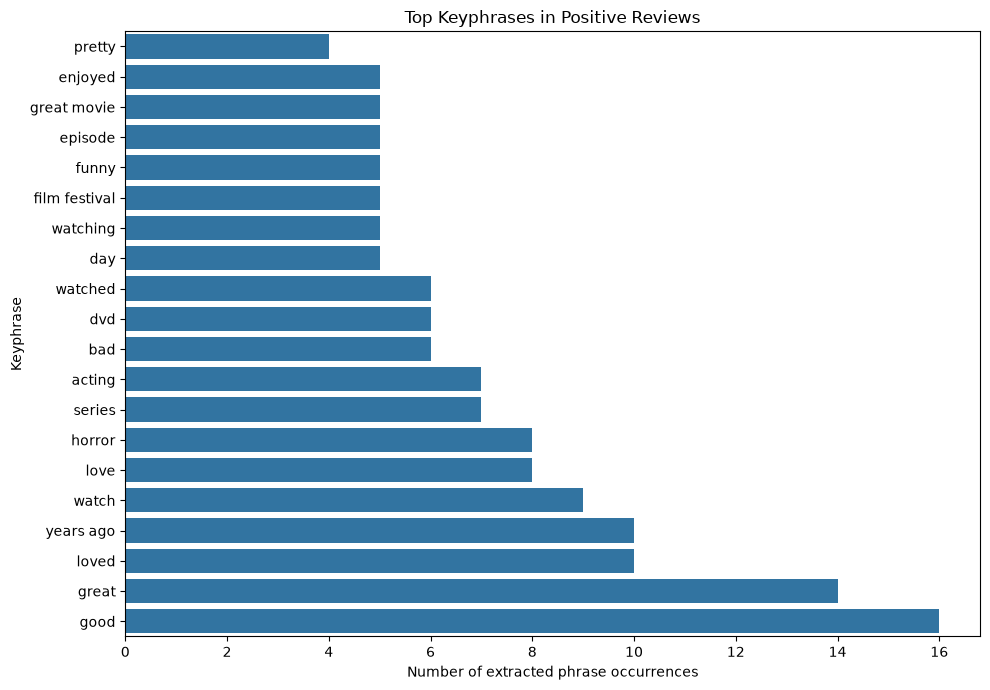

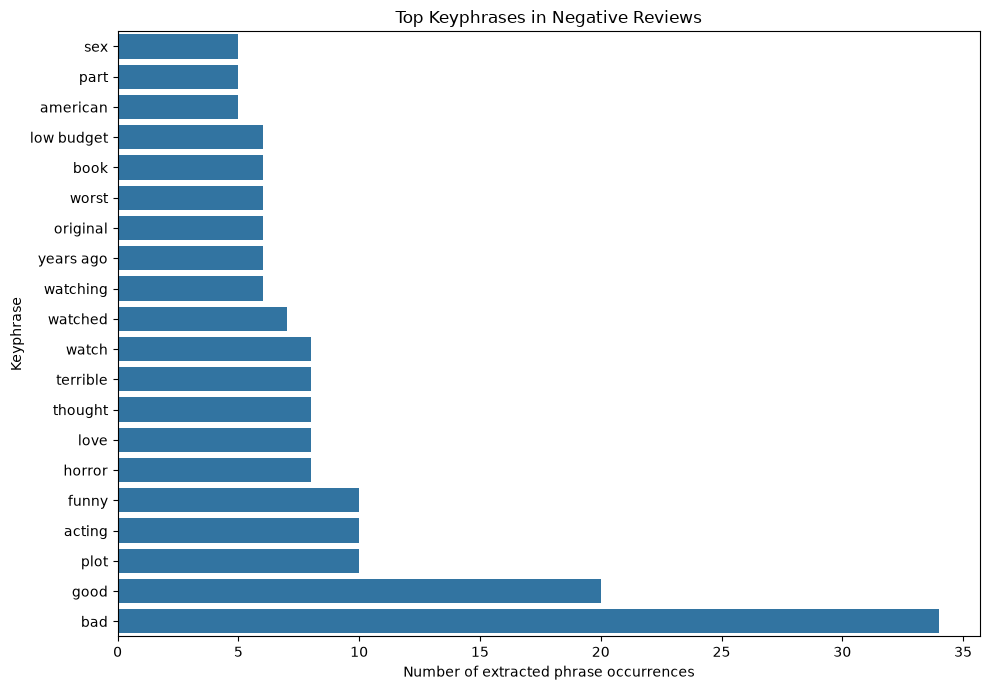

In [8]:
def plot_top_phrases(phrase_counts, title):
    plot_df = pd.DataFrame(
        phrase_counts,
        columns=["Phrase", "Count"]
    ).sort_values("Count", ascending=True)

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=plot_df,
        x="Count",
        y="Phrase"
    )

    plt.title(title)
    plt.xlabel("Number of extracted phrase occurrences")
    plt.ylabel("Keyphrase")
    plt.tight_layout()
    plt.show()


plot_top_phrases(
    positive_phrases,
    "Top Keyphrases in Positive Reviews"
)

plot_top_phrases(
    negative_phrases,
    "Top Keyphrases in Negative Reviews"
)

## Summary and Key Findings

- Used **YAKE (Yet Another Keyword Extractor)** to extract the top 10 keyphrases from individual IMDb movie reviews.
- Analyzed a sample of 500 positive and 500 negative reviews to explore the phrases appearing in each sentiment group.
- Visualized the most frequently extracted keyphrases using horizontal bar charts.
- Positive reviews frequently included terms such as *good*, *great*, and *loved*, while negative reviews frequently included *bad*, *good*, *acting*, and *plot*.
- Observed that some phrases appear in both sentiment groups, showing that keyphrase extraction identifies relevant terms but does not determine sentiment.

**Conclusion:** YAKE provides a simple way to identify important phrases in movie reviews. These extracted phrases can complement sentiment classification by helping users understand some of the topics and expressions present in reviews.

**Limitations:** The analysis uses a sample of the dataset, and phrase counts represent occurrences in the extracted top-10 lists rather than the number of unique reviews containing each phrase.